# Exploratory Data Analysis on Retail Sales Data
**Oasis Infobyte SIP — Data Analytics L1 Task 1** · Steven Manuel Rios

Dataset: *Retail Sales Dataset* (Kaggle, Mohammad Talib): 1,000 transactions from 2023 with customer gender/age, product category, quantity, unit price and total amount.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
def save(name): plt.tight_layout(); plt.savefig(f"screenshots/{name}.png", dpi=110); plt.show()

## 1. Initial inspection

In [2]:
df = pd.read_csv("data/retail_sales_dataset.csv")
print("Shape:", df.shape); print(df.dtypes); print("\nNulls:\n", df.isnull().sum()); print("Duplicates:", df.duplicated().sum())
df["Date"] = pd.to_datetime(df["Date"])
df.head()

Shape: (1000, 9)
Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object

Nulls:
 Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64
Duplicates: 0


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


There are no nulls and no duplicates. `Date` was parsed to datetime.

## 2. Descriptive statistics (mean, median, mode, std)

In [3]:
num = ["Age", "Quantity", "Price per Unit", "Total Amount"]
stats = pd.DataFrame({"mean": df[num].mean(), "median": df[num].median(), "mode": df[num].mode().iloc[0], "std": df[num].std(), "min": df[num].min(), "max": df[num].max()})
stats.round(2)

,mean,median,mode,std,min,max
Age,41.39,42.0,43.0,13.68,18,64
Quantity,2.51,3.0,4.0,1.13,1,4
Price per Unit,179.89,50.0,50.0,189.68,25,500
Total Amount,456.00,135.0,50.0,560.00,25,2000


**Observation:** `Total Amount` is heavily right-skewed: the mean (≈456) is far above the median (135), because a minority of 300/500 unit-price purchases dominate revenue. Ages are spread evenly from 18 to 64, with a mean of ≈41.

## 3. Time-series analysis: monthly and quarterly sales

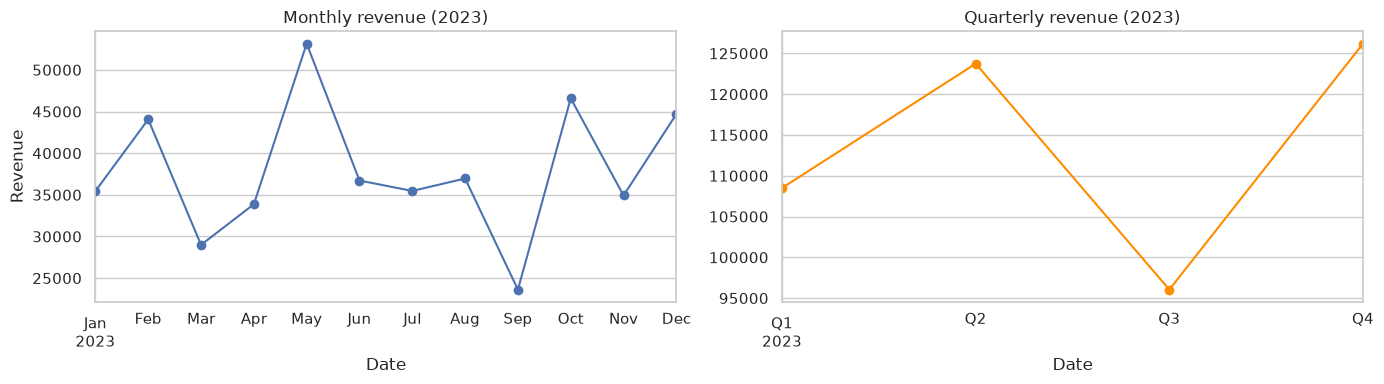

Date
2023-05-31    53150
2023-10-31    46580
2023-12-31    44690
Name: Total Amount, dtype: int64
Date
2023-03-31    108500
2023-06-30    123735
2023-09-30     96045
2023-12-31    126190
Freq: QE-DEC, Name: Total Amount, dtype: int64


In [4]:
ts = df.set_index("Date")["Total Amount"]
monthly = ts[ts.index < "2024-01-01"].resample("ME").sum()
quarterly = ts[ts.index < "2024-01-01"].resample("QE").sum()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
monthly.plot(ax=ax[0], marker="o"); ax[0].set_title("Monthly revenue (2023)"); ax[0].set_ylabel("Revenue")
quarterly.plot(ax=ax[1], marker="o", color="darkorange"); ax[1].set_title("Quarterly revenue (2023)")
save("time_series")
print(monthly.sort_values(ascending=False).head(3)); print(quarterly)

**Observation:** Revenue is volatile month to month. May (≈53k), October (≈47k) and February/December (≈44k) are peaks, and September is the weakest month (≈24k). The dataset has only two January 2024 transactions, so 2024 is excluded from the trend.

## 4. Customer demographics

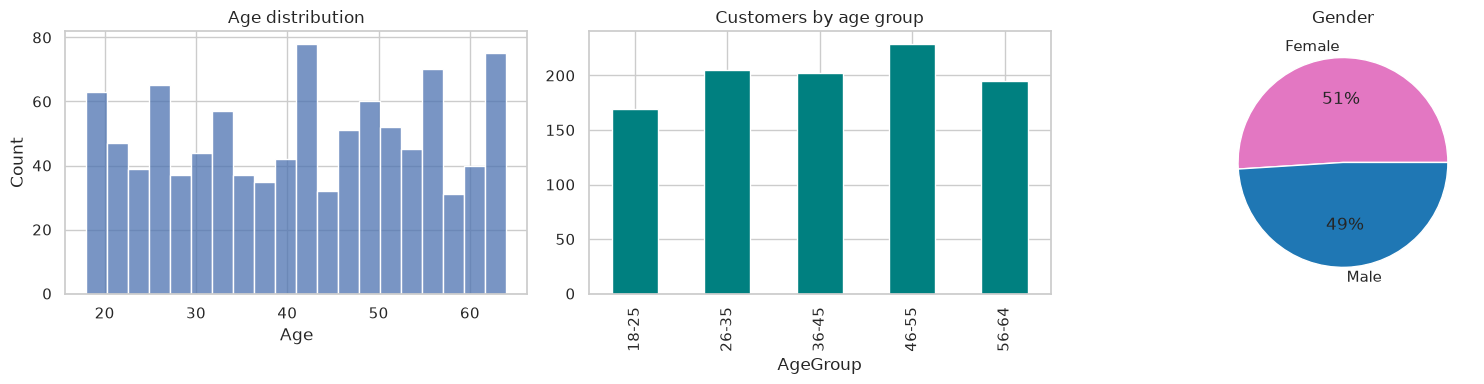

In [5]:
df["AgeGroup"] = pd.cut(df["Age"], [17, 25, 35, 45, 55, 65], labels=["18-25", "26-35", "36-45", "46-55", "56-64"])
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["Age"], bins=20, ax=ax[0]); ax[0].set_title("Age distribution")
df["AgeGroup"].value_counts().sort_index().plot.bar(ax=ax[1], color="teal"); ax[1].set_title("Customers by age group")
df["Gender"].value_counts().plot.pie(ax=ax[2], autopct="%1.0f%%", colors=["#e377c2", "#1f77b4"]); ax[2].set_title("Gender"); ax[2].set_ylabel("")
save("demographics")

In [6]:
pd.crosstab(df["AgeGroup"], df["Product Category"], values=df["Total Amount"], aggfunc="sum")

Product Category,Beauty,Clothing,Electronics
AgeGroup,,,
18-25,31280,26510,26760
26-35,31240,39975,27265
36-45,28405,29550,33915
46-55,34720,30485,35485
56-64,17870,29060,33480


**Observation:** The gender split is close to even (51% female / 49% male). Category preference changes with age: 18–25s spend the most on **Beauty**, 26–35s on **Clothing**, and customers over 45 lean towards **Electronics**.

## 5. Product analysis
The dataset has no product names, so a *product* is defined as a **category × unit-price** SKU (for example, “Electronics @ 500”).

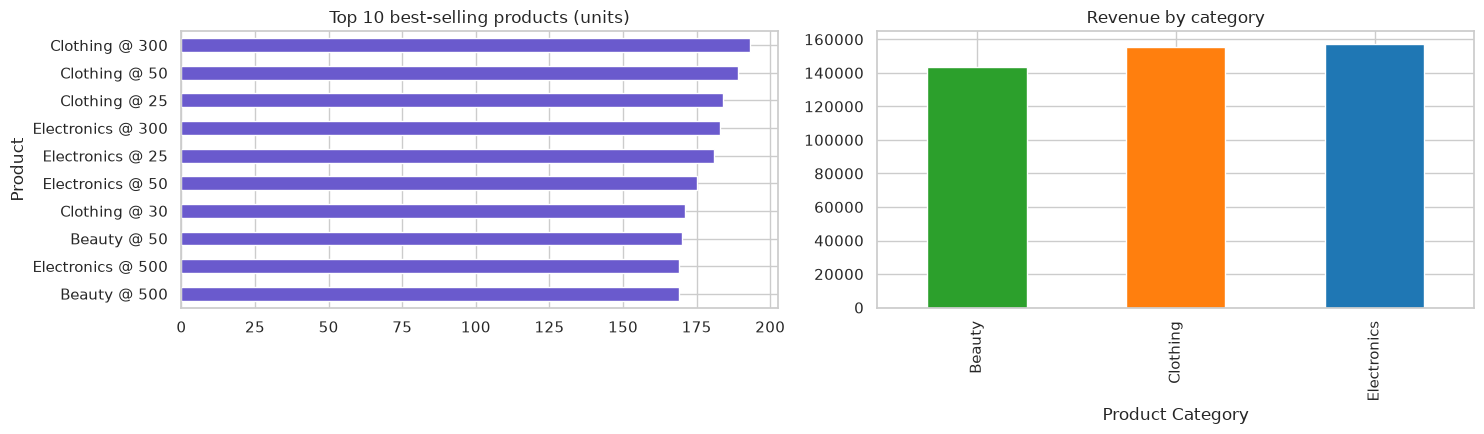

,units,revenue
Product,,
Clothing @ 300,193,57900
Clothing @ 50,189,9450
Clothing @ 25,184,4600
Electronics @ 300,183,54900
Electronics @ 25,181,4525
Electronics @ 50,175,8750
Clothing @ 30,171,5130
Beauty @ 50,170,8500
Electronics @ 500,169,84500


In [7]:
df["Product"] = df["Product Category"] + " @ " + df["Price per Unit"].astype(str)
top10 = df.groupby("Product").agg(units=("Quantity", "sum"), revenue=("Total Amount", "sum")).sort_values("units", ascending=False).head(10)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
top10["units"].sort_values().plot.barh(ax=ax[0], color="slateblue"); ax[0].set_title("Top 10 best-selling products (units)")
df.groupby("Product Category")["Total Amount"].sum().sort_values().plot.bar(ax=ax[1], color=["#2ca02c", "#ff7f0e", "#1f77b4"]); ax[1].set_title("Revenue by category")
save("products"); top10

**Observation:** The three categories earn almost the same revenue: Electronics ≈156.9k, Clothing ≈155.6k and Beauty ≈143.5k. Unit sales are fairly flat across SKUs (169–193 units for the top 10, led by Clothing @ 300). Revenue is concentrated in the 300/500 SKUs: Electronics @ 500 and Beauty @ 500 alone bring in 84.5k each.

## 6. Correlation heatmap

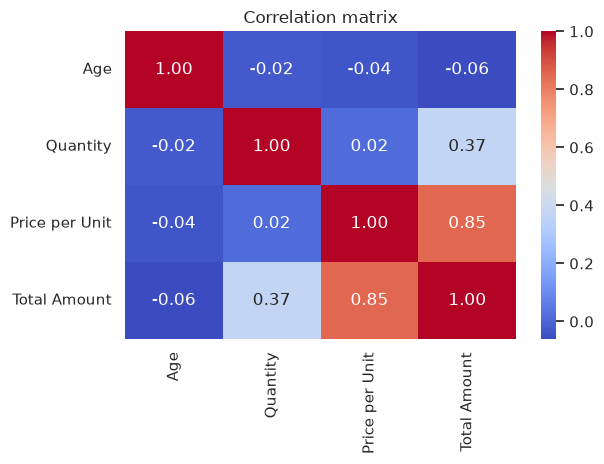

In [8]:
sns.heatmap(df[num].corr(), annot=True, cmap="coolwarm", fmt=".2f"); plt.title("Correlation matrix"); save("correlation")

**Observation:** `Total Amount` is driven by `Price per Unit` (r ≈ 0.85) much more than by `Quantity` (r ≈ 0.37). Age has essentially no linear relationship with spend.

## 7. Additional insight: price does not reduce quantity

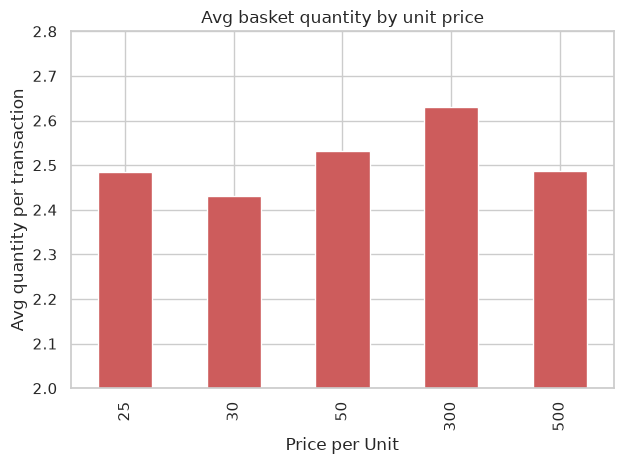

Price per Unit
25     2.485714
30     2.431694
50     2.530806
300    2.629442
500    2.487437
Name: Quantity, dtype: float64

In [9]:
q = df.groupby("Price per Unit")["Quantity"].mean()
q.plot.bar(color="indianred"); plt.ylabel("Avg quantity per transaction"); plt.title("Avg basket quantity by unit price"); plt.ylim(2, 2.8); save("price_vs_quantity"); q

**Non-obvious insight:** Customers buy about the same number of units (≈2.4–2.6) whether an item costs 25 or 500. This suggests demand is price-inelastic within each category, so premium items do not lose basket volume.

## Conclusion & business recommendations
1. **Plan inventory and promotions around the peaks.** May, October and December are the strongest months, and September is the weakest (−55% vs May). Run a September promotion to fill the trough, and stock up ahead of Q4, which is the best quarter at 126k.
2. **Target categories by age.** Market Beauty to 18–25s, Clothing to 26–35s, and Electronics to customers over 45, who spend the most on it.
3. **Push premium SKUs.** Unit price explains most of the revenue variation (r = 0.85), and basket quantity does not fall at higher prices. Upselling to the 300/500 tiers, for example with bundles, lifts revenue without losing volume.
4. **Use gender-neutral campaigns.** Spend and customer counts are almost identical across genders, so gender-specific targeting adds little.